# **Step 7 – Minería de datos: dimensiones de la atención e índice de prioridad**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 7 (Fayyad, Piatetsky-Shapiro y Smyth, 1996):* «Data mining: searching for patterns of interest: classification trees, regression, clustering, and so forth.»

Se aplica el algoritmo elegido en el Step 6: un **PCA con 2 componentes** sobre las 10 variables de atención estandarizadas.

Entrada: `datos/3_transformados/step4_ninos_atencion.csv` (158 niños) y `cifras_step6.json` (número de componentes).

Salidas:
- `datos/4_resultados/step7_modelo_pca.json`: medias, desvíos y cargas, para recalcular el índice con datos nuevos (Step 9);
- `step7_puntajes.csv`: puntaje, cuadrante e índice de cada niño;
- `step7_cargas_pca.csv`.

## Librerías y datos

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
sys.path.insert(0, "..")
from src.atencion import VARS, cuadrante, PRIORIDAD
TRA, RES, FIG = Path("../datos/3_transformados"), Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 2026
at = pd.read_csv(TRA/"step4_ninos_atencion.csv", sep="|")
K = json.load(open(RES/"cifras_step6.json"))["pca_componentes"]
media, desv = at[VARS].mean().to_numpy(), at[VARS].std(ddof=0).to_numpy()
Z = (at[VARS].to_numpy(float) - media) / desv
print("Niños:", len(at), "| variables:", len(VARS), "| componentes (Step 6):", K)

Niños: 158 | variables: 10 | componentes (Step 6): 2


## 1. Ajuste del modelo
El signo de un componente es arbitrario. Se fija para que la permanencia **aumente** con el tiempo en el hogar y la intensidad **aumente** con el acompañamiento; así, un puntaje alto se lee siempre igual.

In [2]:
pca = PCA(K).fit(Z); W = pca.components_.copy()
signo = np.sign([W[0, VARS.index("tiempo_hogar")], W[1, VARS.index("p_acompan")]]); W = W * signo[:, None]
NOMBRES = ["Permanencia", "Intensidad psicosocial"]
cargas = pd.DataFrame(W.T, index=VARS, columns=NOMBRES)
var_exp = 100 * pca.explained_variance_ratio_
print("Varianza explicada:", var_exp.round(1), "% | acumulada:", round(var_exp.sum(), 1), "%")
print(cargas.round(2).to_string())
json.dump({"variables": VARS, "media": media.tolist(), "desv": desv.tolist(), "cargas": W.tolist(), "nombres": NOMBRES,
           "varianza_explicada": var_exp.round(2).tolist()}, open(RES/"step7_modelo_pca.json", "w"), indent=1)
cargas.to_csv(RES/"step7_cargas_pca.csv", sep="|")

Varianza explicada: [23.8 17.1] % | acumulada: 40.9 %
                  Permanencia  Intensidad psicosocial
tiempo_hogar             0.43                   -0.06
legal_definitiva         0.48                    0.09
p_acompan               -0.27                    0.46
p_psicoter              -0.08                    0.32
p_taller                -0.27                    0.37
p_salud_mental           0.24                    0.53
p_pti_vencido           -0.36                    0.02
p_pti_no_tiene           0.42                    0.01
discap_sev               0.07                    0.38
anemia_alguna            0.25                    0.32


**Lectura de las cargas.** Una carga positiva grande significa que la variable sube cuando sube el puntaje de esa dimensión.
- **Permanencia:** situación legal definitiva (+0,48), tiempo en el hogar (+0,43) y meses sin PTI (+0,42), frente a PTI vencido (−0,36), acompañamiento y talleres (−0,27).
- **Intensidad psicosocial:** salud mental especializada (+0,53), acompañamiento (+0,46), discapacidad (+0,38), talleres (+0,37), psicoterapia y anemia (+0,32). Prácticamente no depende del tiempo en el hogar (−0,06).

## 2. Puntajes, cuadrantes e índice de prioridad
Cada niño recibe un puntaje en cada dimensión (0 = promedio de la institución). Los cuadrantes se definen por el signo de los dos puntajes. El **cuadrante de prioridad** reúne a los niños con permanencia por encima del promedio e intensidad por debajo. Dentro de él, el **índice de prioridad** = permanencia − intensidad: cuanto mayor, más tiempo en la institución y menos atención.

cuadrante
Prioridad: larga permanencia, baja atención    51
Reciente, baja atención                        48
Reciente, atención activa                      39
Larga permanencia, atención activa             20


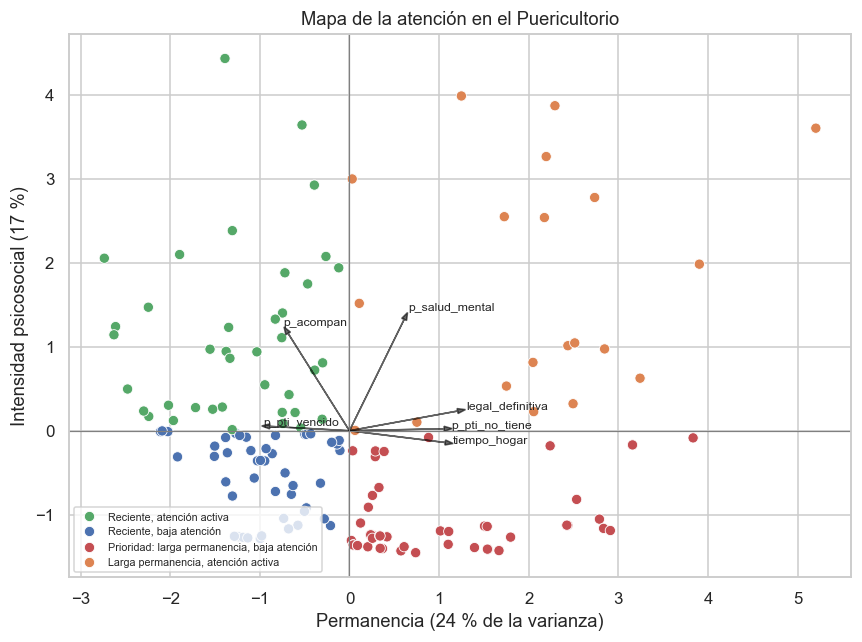

In [3]:
P = Z @ W.T
at["permanencia"], at["intensidad"] = P[:, 0], P[:, 1]
at["cuadrante"] = cuadrante(at["permanencia"], at["intensidad"])
at["indice_prioridad"] = np.where(at["cuadrante"] == PRIORIDAD, at["permanencia"] - at["intensidad"], np.nan)
print(at["cuadrante"].value_counts().to_string())
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=at, x="permanencia", y="intensidad", hue="cuadrante", s=45, ax=ax,
                palette={PRIORIDAD: "#C44E52", "Larga permanencia, atención activa": "#DD8452", "Reciente, atención activa": "#55A868", "Reciente, baja atención": "#4C72B0"})
ax.axhline(0, c="gray", lw=.8); ax.axvline(0, c="gray", lw=.8)
for v in ["tiempo_hogar", "legal_definitiva", "p_pti_no_tiene", "p_acompan", "p_salud_mental", "p_pti_vencido"]:
    i = VARS.index(v); ax.arrow(0, 0, 2.5 * W[0, i], 2.5 * W[1, i], color="black", alpha=.6, head_width=.06); ax.text(2.7 * W[0, i], 2.7 * W[1, i], v, fontsize=8)
ax.set_xlabel(f"Permanencia ({var_exp[0]:.0f} % de la varianza)"); ax.set_ylabel(f"Intensidad psicosocial ({var_exp[1]:.0f} %)")
ax.set_title("Mapa de la atención en el Puericultorio"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(FIG/"step7_mapa_atencion.png", bbox_inches="tight"); plt.show()

## 3. Robustez: ¿los niños de prioridad lo serían con otra muestra?
Se repite el PCA en 300 remuestreos de niños (bootstrap). En cada uno se alinean los componentes con los originales (mismo orden y signo), se proyecta a **todos** los niños y se anota si caen en el cuadrante de prioridad. La **estabilidad** de cada niño es el porcentaje de remuestreos en que queda en ese cuadrante.

In [4]:
rng = np.random.default_rng(SEED); veces = np.zeros(len(at))
for b in range(300):
    Cb = PCA(K).fit(Z[rng.choice(len(Z), len(Z))]).components_
    orden = [int(np.argmax(np.abs(Cb @ W[c]))) for c in range(K)]
    Cb = np.array([Cb[o] * np.sign(Cb[o] @ W[c]) for c, o in enumerate(orden)])
    Pb = Z @ Cb.T; veces += (Pb[:, 0] > 0) & (Pb[:, 1] < 0)
at["estabilidad_prioridad"] = 100 * veces / 300
prio = at["cuadrante"] == PRIORIDAD
n_estables = int((at.loc[prio, "estabilidad_prioridad"] >= 80).sum())
print(f"Niños en prioridad: {int(prio.sum())} | estables (≥ 80 % de remuestreos): {n_estables} | estabilidad mediana: {at.loc[prio, 'estabilidad_prioridad'].median():.0f} %")
print("Niños fuera de prioridad que caen en ella en ≥ 50 % de remuestreos:", int(((~prio) & (at["estabilidad_prioridad"] >= 50)).sum()))

Niños en prioridad: 51 | estables (≥ 80 % de remuestreos): 23 | estabilidad mediana: 77 %
Niños fuera de prioridad que caen en ella en ≥ 50 % de remuestreos: 0


**Interpretación.** La frontera del cuadrante es **nítida hacia afuera**: ningún niño que hoy está fuera de prioridad cae en ella en la mitad o más de los remuestreos. Hacia adentro hay dos niveles: **23 de los 51 niños (45 %)** quedan en prioridad en al menos el 80 % de los remuestreos (estabilidad mediana 77 %; mínima 41 %). Los otros 28 están cerca del borde del cuadrante (intensidad o permanencia cercanas al promedio). Por eso la lista del Step 9 distingue **"revisar primero"** (los 23 estables) de **"revisar"** (el resto).

## 4. Guardado

In [5]:
cols = ["id_nna", "permanencia", "intensidad", "cuadrante", "indice_prioridad", "estabilidad_prioridad", "edad", "sexo_m", "upe", "tiempo_hogar",
        "legal_definitiva", "p_sin_soporte", "p_acompan", "p_psicoter", "p_salud_mental", "p_pti_no_tiene", "p_pti_vencido", "discap_sev", "anemia_alguna"]
at[cols].sort_values("indice_prioridad", ascending=False).to_csv(RES/"step7_puntajes.csv", sep="|", index=False)
print("Guardado:", at[cols].shape)

Guardado: (158, 19)


## Verificación y cifras de este notebook

In [6]:
assert K == 2 and round(var_exp.sum(), 1) == 40.9 and int(prio.sum()) == 51 and n_estables == 23
assert int(((~prio) & (at["estabilidad_prioridad"] >= 50)).sum()) == 0
cifras = {"varianza": [round(float(x), 1) for x in var_exp], "cuadrantes": at["cuadrante"].value_counts().to_dict(), "ninos_prioridad": int(prio.sum()),
          "prioridad_estables_80": n_estables, "estabilidad_mediana": round(float(at.loc[prio, "estabilidad_prioridad"].median()), 1),
          "cargas": cargas.round(2).to_dict()}
json.dump(cifras, open(RES/"cifras_step7.json", "w"), indent=1); cifras

{'varianza': [23.8, 17.1],
 'cuadrantes': {'Prioridad: larga permanencia, baja atención': 51,
  'Reciente, baja atención': 48,
  'Reciente, atención activa': 39,
  'Larga permanencia, atención activa': 20},
 'ninos_prioridad': 51,
 'prioridad_estables_80': 23,
 'estabilidad_mediana': 76.7,
 'cargas': {'Permanencia': {'tiempo_hogar': 0.43,
   'legal_definitiva': 0.48,
   'p_acompan': -0.27,
   'p_psicoter': -0.08,
   'p_taller': -0.27,
   'p_salud_mental': 0.24,
   'p_pti_vencido': -0.36,
   'p_pti_no_tiene': 0.42,
   'discap_sev': 0.07,
   'anemia_alguna': 0.25},
  'Intensidad psicosocial': {'tiempo_hogar': -0.06,
   'legal_definitiva': 0.09,
   'p_acompan': 0.46,
   'p_psicoter': 0.32,
   'p_taller': 0.37,
   'p_salud_mental': 0.53,
   'p_pti_vencido': 0.02,
   'p_pti_no_tiene': 0.01,
   'discap_sev': 0.38,
   'anemia_alguna': 0.32}}}